# FIFA World Cup matches analysis

An exploratory analysis of about 900 World Cup matches (one row per match), made to practice cleaning, transforming and visualizing data with pandas and matplotlib.

**Data:** `world_cup_matches1.csv` (https://www.kaggle.com/datasets/abhijitdahatonde/fifa-world-cup-all-dataset/discussion?sort=recent-comments)
**Columns:** ID, Year, Stage, Home Team, Home Goals, Away Goals, Away Team, Host Team or Not

**Questions:**
1. Do matches have more or fewer goals over the years?
2. Do host teams have an advantage?
3. Which teams are the most successful?

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("world_cup_matches1.csv")

df.head(10)


,ID,Year,Stage,Home Team,Home Goals,Away Goals,Away Team,Host Team or Not
0,1,1930,Group stage,France,4,1,Mexico,0
1,2,1930,Group stage,United States,3,0,Belgium,0
2,3,1930,Group stage,Yugoslavia,2,1,Brazil,0
3,4,1930,Group stage,Romania,3,1,Peru,0
4,5,1930,Group stage,Argentina,1,0,France,0
5,6,1930,Group stage,Chile,3,0,Mexico,0
6,7,1930,Group stage,Yugoslavia,4,0,Bolivia,0
7,8,1930,Group stage,United States,3,0,Paraguay,0
8,9,1930,Group stage,Uruguay,1,0,Peru,1
9,10,1930,Group stage,Chile,1,0,France,0


## Data checks

Before analyzing, I check the size and types of the data, the range of years, the values in `Stage` and `Host Team or Not`, duplicate IDs, and the list of teams.

In [22]:
print(df["Year"].min(), df["Year"].max(), df["Year"].nunique())
print(df["Stage"].value_counts())
print(df["Host Team or Not"].value_counts())
print("duplicate IDs:", df["ID"].duplicated().sum())
print(sorted(set(df["Home Team"]) | set(df["Away Team"])))
df.info()

1930 2018 21
Stage
Group stage           528
Round of 16            89
First group stage      84
Quarter-finals         66
Semi-finals            36
Second group stage     36
Final                  20
Third place            19
First round            16
Final round             6
Name: count, dtype: int64
Host Team or Not
0    782
1    118
Name: count, dtype: int64
duplicate IDs: 0
['Algeria', 'Angola', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Cameroon', 'Canada', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Croatia', 'Cuba', 'Czech Republic', 'Czechoslovakia', 'DR Congo', 'Denmark', 'East Germany', 'Ecuador', 'Egypt', 'El Salvador', 'England', 'France', 'Germany', 'Ghana', 'Greece', 'Haiti', 'Honduras', 'Hungary', 'Iceland', 'Indonesia', 'Iran', 'Iraq', 'Israel', 'Italy', 'Ivory Coast', 'Jamaica', 'Japan', 'Kuwait', 'Mexico', 'Morocco', 'Netherlands', 'New Zealand', 'Nigeria', 'North Korea', 'Northern Ireland', 'Norway',

**What I found:**
- No missing values.
- Years from 1930 to 2018, 21 tournaments, 900 matches.
- No duplicate IDs.
- Some teams no longer exist under that name (for example Czechoslovakia, East Germany and Yugoslavia).

**Decision:** I keep the team names as they are. Merging a team with its successor is a judgment call and I do not want to guess, so statistics per team count a country and its predecessor separately.

## New columns

- `Total Goals`: home goals + away goals
- `Winner`: the winning team, or "Draw" if the score is level
- `Goal Difference`: absolute difference between the two scores

If a knockout match ended level, "Draw" means level after normal play. The data has no information about penalty shootouts, so the real winner is not recorded.

In [23]:
df["Total Goals"] = df["Home Goals"] + df["Away Goals"]

conditions = [
    df["Home Goals"] > df["Away Goals"], 
    df["Away Goals"] > df["Home Goals"],  
]

choices = [df["Home Team"], df["Away Team"]]

df["Winner"] = np.select(conditions, choices, default="Draw")

df["Goal Difference"] = abs(df["Home Goals"] - df["Away Goals"])
df




,ID,Year,Stage,Home Team,Home Goals,Away Goals,Away Team,Host Team or Not,Total Goals,Winner,Goal Difference
0,1,1930,Group stage,France,4,1,Mexico,0,5,France,3
1,2,1930,Group stage,United States,3,0,Belgium,0,3,United States,3
2,3,1930,Group stage,Yugoslavia,2,1,Brazil,0,3,Yugoslavia,1
3,4,1930,Group stage,Romania,3,1,Peru,0,4,Romania,2
4,5,1930,Group stage,Argentina,1,0,France,0,1,Argentina,1
...,...,...,...,...,...,...,...,...,...,...,...
895,896,2018,Quarter-finals,Russia,2,2,Croatia,1,4,Draw,0
896,897,2018,Semi-finals,France,1,0,Belgium,0,1,France,1
897,898,2018,Semi-finals,Croatia,2,1,England,0,3,Croatia,1
898,899,2018,Third place,Belgium,2,0,England,0,2,Belgium,2


## Question 1: Do goals per match change over the years?

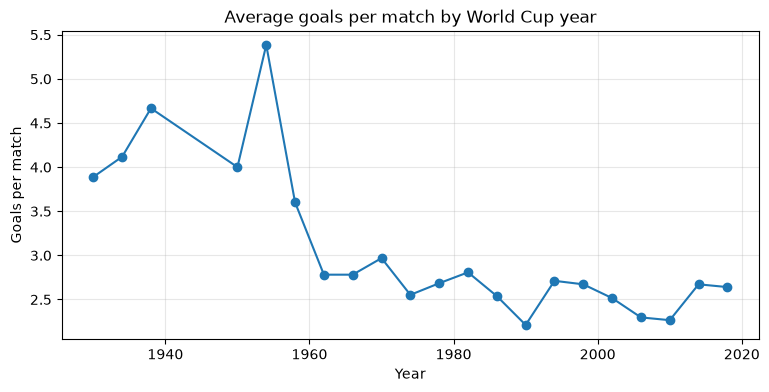

,avg_goals,matches
Year,,
1930,3.888889,18
1934,4.117647,17
1938,4.666667,18
1950,4.000000,22
1954,5.384615,26
1958,3.600000,35
1962,2.781250,32
1966,2.781250,32
1970,2.968750,32


In [24]:
stats_by_year = df.groupby("Year").agg(
    avg_goals=("Total Goals", "mean"),
    matches=("ID", "count"),
)

plt.figure(figsize=(9, 4))
plt.plot(stats_by_year["avg_goals"], marker="o")
plt.title("Average goals per match by World Cup year")
plt.xlabel("Year")
plt.ylabel("Goals per match")
plt.grid(alpha=0.3)
plt.show()

stats_by_year

### Findings

Average goals per match were high in the early tournaments (about 3.9 to 5.4 from 1930 to 1954) and fell to roughly 2.2 to 3.0 from 1962 onwards. Since 1998 the average has stayed between about 2.3 and 2.7. The early tournaments had only 17 to 26 matches each, so their averages are less stable.

## Question 2: Do host teams have an advantage?

In [25]:
df["Result"] = np.select(
    [df["Home Goals"] > df["Away Goals"], df["Away Goals"] > df["Home Goals"]],
    ["Home win", "Away win"],
    default="Draw",
)

pd.crosstab(df["Host Team or Not"], df["Result"], normalize="index").round(3)

Result,Away win,Draw,Home win
Host Team or Not,,,
0,0.226,0.226,0.547
1,0.178,0.186,0.636


In [26]:
pd.crosstab(df["Host Team or Not"], df["Result"])

Result,Away win,Draw,Home win
Host Team or Not,,,
0,177,177,428
1,21,22,75


### Findings

When the Home Team is the tournament host, it wins 63.6% of matches (75 of 118). When it is not the host, it wins 54.7% (428 of 782). Hosts win about 9 percentage points more often.

The host sample is small (118 matches), so this difference is close to what random noise could produce, and it does not support a firm conclusion. Hosts are also often strong teams (e.g. Brazil, Germany, Italy), so I cannot separate the effect of hosting from the effect of team strength.

Even when Host = 0, the Home Team wins far more often than the Away Team (54.7% vs 22.6%). I suspect the stronger or seeded team is listed first, but the dataset has no strength column to check this.

## Question 3: Which teams are the most successful?

I measure success by win rate: the share of a team's matches that it won. To avoid misleading percentages from small samples, I only include teams with at least 20 matches.

In [28]:
home = df[["Year", "Home Team", "Home Goals", "Away Goals"]].copy()
home.columns = ["Year", "Team", "Goals For", "Goals Against"]

away = df[["Year", "Away Team", "Away Goals", "Home Goals"]].copy()
away.columns = ["Year", "Team", "Goals For", "Goals Against"]

team_matches = pd.concat([home, away], axis=0, ignore_index=True)

conditions = [
    team_matches["Goals For"] > team_matches["Goals Against"],
    team_matches["Goals For"] < team_matches["Goals Against"],
]
choices = ["Win", "Lose"]

team_matches["Result"] = np.select(conditions, choices, default="Draw")
team_matches["Win"] = team_matches["Result"] == "Win"

teams = team_matches.groupby("Team").agg({
    "Result": "count",
    "Win": "sum",
})
teams.columns = ["Matches", "Wins"]
teams = teams.sort_values("Wins", ascending=False)

teams["Win Rate"] = ((teams["Wins"] / teams["Matches"]) * 100).round(1)

enough_matches = teams["Matches"] >= 20

teams_filtered = teams[enough_matches]
teams_filtered = teams_filtered.sort_values("Win Rate", ascending= False)
print(len(teams), len(teams_filtered))
teams_filtered.head(10)

81 33


,Matches,Wins,Win Rate
Team,,,
Brazil,109,73,67.0
Germany,109,67,61.5
Italy,83,45,54.2
Netherlands,50,27,54.0
Argentina,81,43,53.1
France,66,34,51.5
Croatia,23,11,47.8
Spain,63,30,47.6
Poland,34,16,47.1


In [29]:
teams.head(10)

,Matches,Wins,Win Rate
Team,,,
Brazil,109,73,67.0
Germany,109,67,61.5
Italy,83,45,54.2
Argentina,81,43,53.1
France,66,34,51.5
Spain,63,30,47.6
England,69,29,42.0
Netherlands,50,27,54.0
Uruguay,56,24,42.9


### Findings

Brazil has the highest win rate (67.0% of 109 matches), followed by Germany (61.5% of 109). Italy, the Netherlands, Argentina and France follow at around 51-54%.

Success by win rate and success by total wins are not the same thing. England, Uruguay and Belgium are in the top 10 by number of wins, but not by win rate. Croatia, Poland and Hungary are the opposite: they win often, but over far fewer matches (23, 34 and 32), so their percentages are less reliable.

Limitations: the 20-match threshold is my own choice. Teams that no longer exist, such as East Germany, are counted separately from their successors. Penalty shootouts are not recorded, so knockout draws count as draws.

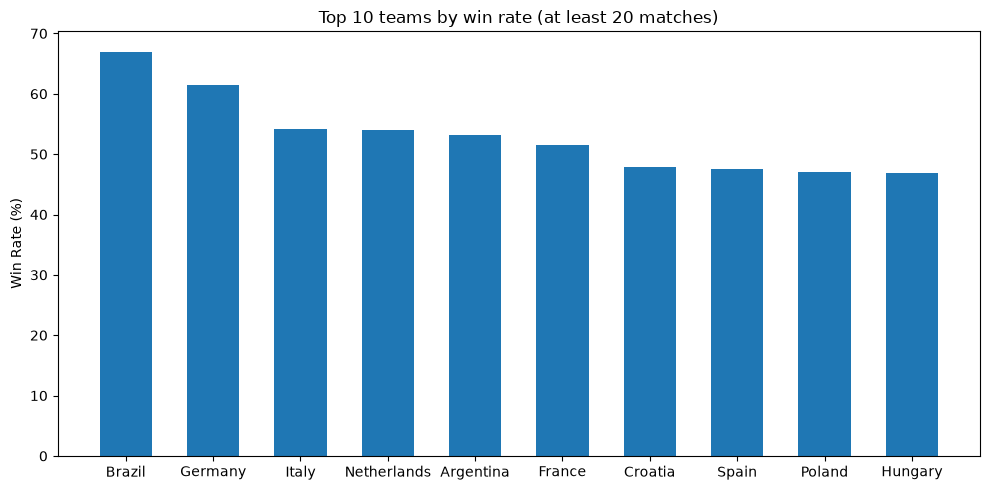

In [30]:
top10 = teams_filtered.head(10)

plt.figure(figsize=(10, 5))
plt.bar(top10.index, top10["Win Rate"] ,width=0.6)
plt.title("Top 10 teams by win rate (at least 20 matches)")
plt.ylabel("Win Rate (%)")
plt.tight_layout()
plt.show()